In [2]:
# Import All require library
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [3]:
df = pd.read_csv("smartcart_customers.csv")

In [4]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


#### Data Preprocessing

In [5]:
#Handling Missing Value 

df["Income"] = df["Income"].fillna(df["Income"].median)

## Feature engineering

In [6]:
# Age
df["Age"] = 2026 - df["Year_Birth"]

In [7]:
# Custome Joining Date
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True)

reference_date = df["Dt_Customer"].max()

df["Custome_Tenure_Days"] = (reference_date - df["Dt_Customer"]).dt.days

In [8]:
# Spending
df["Total_spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"]  + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]

In [9]:
# Kids and Teen

df["Total_children"] = df["Teenhome"] + df["Kidhome"]

In [10]:
# Edication 
df["Education"] = df["Education"].replace(
    {
        "Basic":"Undergraduate" , "2n Cycle":"Undergraduate",
        "Graduation":"Graduate", 
        "PhD":"Postgraduate","Master":"Postgraduate"
    }
)
# Undergraduate , Graduate, Postgraduate

In [11]:
# Marital Status
df["Living_with"] = df["Marital_Status"].replace(
    {
        "Married":"Partner" , "Together":"Partner",
        "Single":"Alone", "Divorced":"Alone", "Widow":"Alone" , "Absurd":"Alone", "YOLO":"Alone"   
    }
)

# Drop Column

In [12]:
cols = ["ID", "Year_Birth", "Marital_Status", "Teenhome", "Kidhome", "Dt_Customer"]
spending_col = ['MntWines', 'MntFruits','MntMeatProducts', 'MntFishProducts', 'MntSweetProducts','MntGoldProds']
col_to_drop = spending_col + cols
df_cleaned = df.drop(columns = col_to_drop)

In [13]:
df_cleaned.shape

(2240, 15)

In [14]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Custome_Tenure_Days,Total_spending,Total_children,Living_with
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


# Outliers

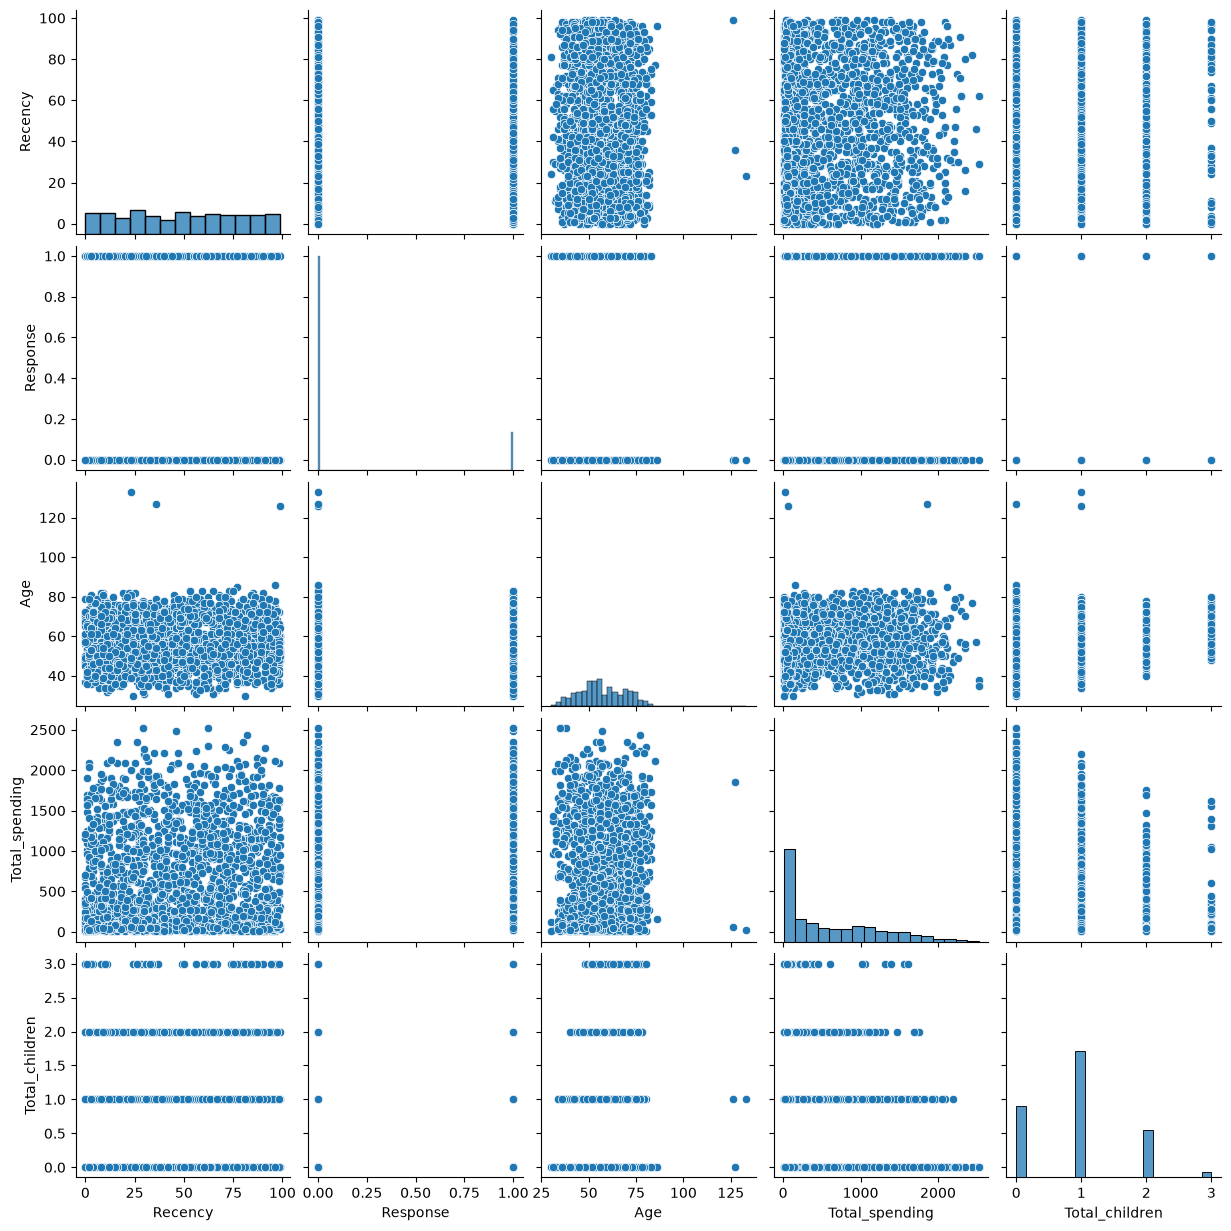

In [15]:
cols = ["Income","Recency", "Response", "Age", "Total_spending", "Total_children"]

# Releative plots of some feature 
sns.pairplot(df_cleaned[cols])

In [16]:
# Remove Outliers 
print("Data size with outliers :", len(df_cleaned))

df_cleaned["Income"] = pd.to_numeric(
    df_cleaned["Income"], errors="coerce"
)

df_cleaned = df_cleaned[(df_cleaned["Age"] < 90)]
df_cleaned = df_cleaned[(df_cleaned["Income"] < 600_000)]

Data size with outliers : 2240


In [17]:
print("Data size without outliers :", len(df_cleaned))

Data size without outliers : 2212


# HeatMap

<Axes: >

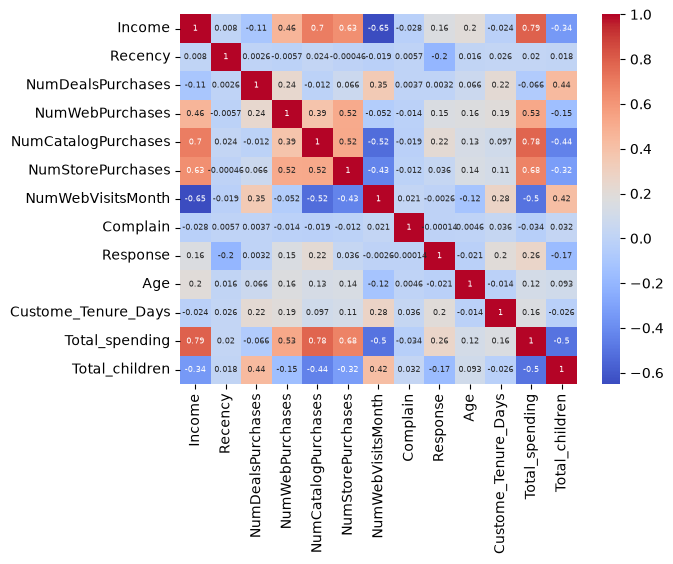

In [18]:
corr = df_cleaned.corr(numeric_only = True)
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    annot_kws={"size":6}
)

# Encoding Feature

In [25]:
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder()
cat_cols = ["Education", "Living_with"]
encodind_col = ohe.fit_transform(df_cleaned[cat_cols])

In [26]:
enc_df = pd.DataFrame(encodind_col.toarray(), columns=ohe.get_feature_names_out(cat_cols), index=df_cleaned.index)

In [27]:
df_encoded = pd.concat([df_cleaned.drop(columns=cat_cols), enc_df], axis=1)
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Custome_Tenure_Days,Total_spending,Total_children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_with_Alone,Living_with_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0


# Scaling

In [28]:
from sklearn.preprocessing import StandardScaler

X = df_encoded

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Visualizating

In [29]:
# 2D
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

array([0.23258254, 0.11390916, 0.10418299])

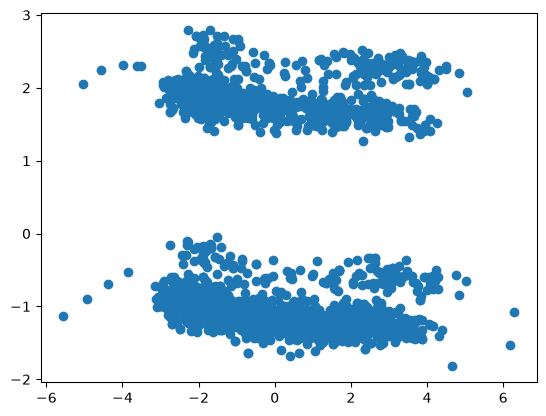

In [30]:
#plot
plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
)
pca.explained_variance_ratio_

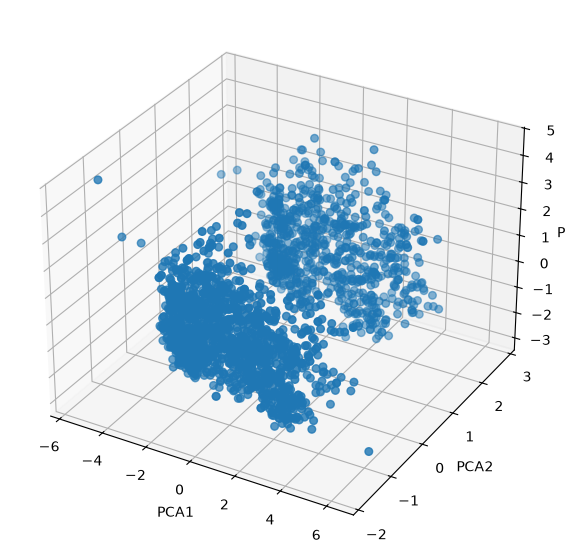

In [31]:
# 3D plot
fig = plt.figure(figsize=(8, 7))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    X_pca[:, 2],
    s=30
)

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")

plt.show()

# Analyse K Value 
## 1. Elbow Method

In [32]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

wcss = []

for k in range(1,11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)

In [33]:
knee = KneeLocator(
    range(1,11),
    wcss,
    curve="convex",
    direction="decreasing"
)
optimal_k = knee.elbow
print("Optimal K :", optimal_k)

Optimal K : 4


Text(0.5, 1.0, 'Elbow Method plot')

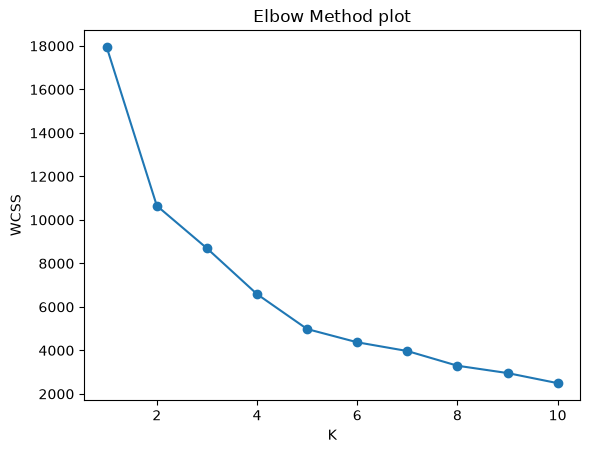

In [34]:
# Chek ploting plot
plt.plot(
    range(1,11),
    wcss,
    marker="o"
)

plt.xlabel("K")
plt.ylabel("WCSS")
plt.title("Elbow Method plot")

## 2. Silhouette Score

In [35]:
from sklearn.metrics import silhouette_score

scores = []

for k in range(2,11):
    kmean = KMeans(n_clusters=k, random_state=42)
    labels = kmean.fit_predict(X_pca)
    scores.append(silhouette_score(X_pca, labels))

Text(0.5, 1.0, 'Elbow Method plot')

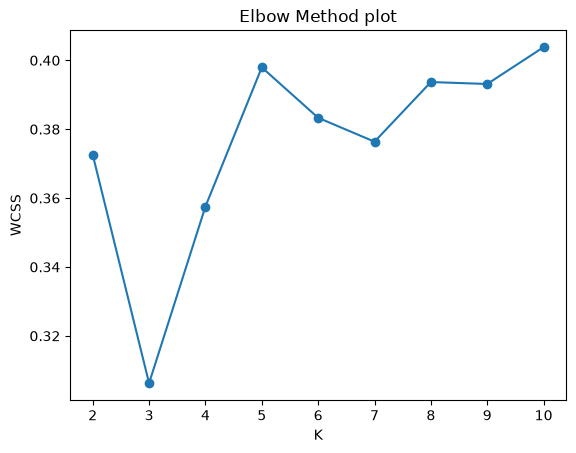

In [36]:
# Plot
plt.plot(
    range(2,11),
    scores,
    marker="o"
)

plt.xlabel("K")
plt.ylabel("WCSS")
plt.title("Elbow Method plot")

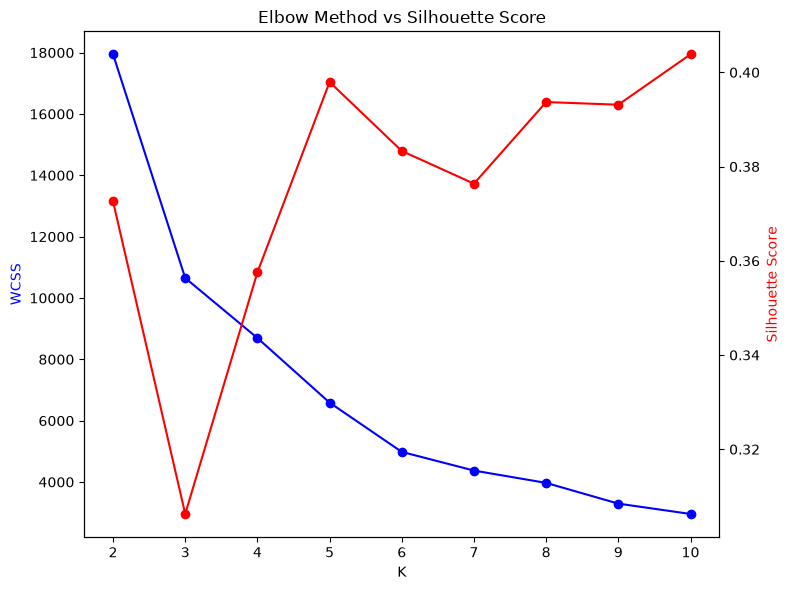

In [37]:

# Combine Plot
K_range = range(2, 11)

fig, ax1 = plt.subplots(figsize=(8, 6))

# Plot WCSS
ax1.plot(
    K_range,
    wcss[:len(K_range)],
    color="blue",
    marker="o"
)

ax1.set_xlabel("K")
ax1.set_ylabel("WCSS", color="blue")

# Second Y-axis
ax2 = ax1.twinx()

ax2.plot(
    K_range,
    scores[:len(K_range)],
    color="red",
    marker="o"
)

ax2.set_ylabel("Silhouette Score", color="red")

plt.title("Elbow Method vs Silhouette Score")
plt.tight_layout()
plt.show()


# Clustring
## 1.K-Means

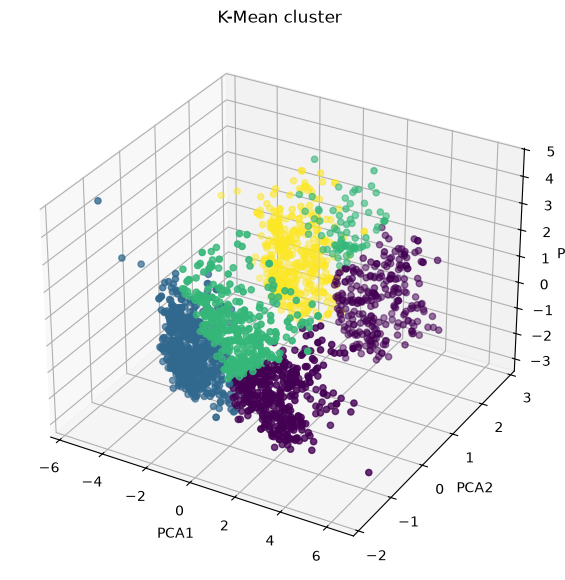

In [45]:
from sklearn.cluster import KMeans

k = 4

kmeans = KMeans(
    n_clusters=4,
    random_state = 42
)

lables = kmeans.fit_predict(X_pca)
# plot
fig = plt.figure(figsize=(8, 7))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    X_pca[:, 2],
    c=lables
)

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("K-Mean cluster")

plt.show()

## 2.AgglomerativeClustering

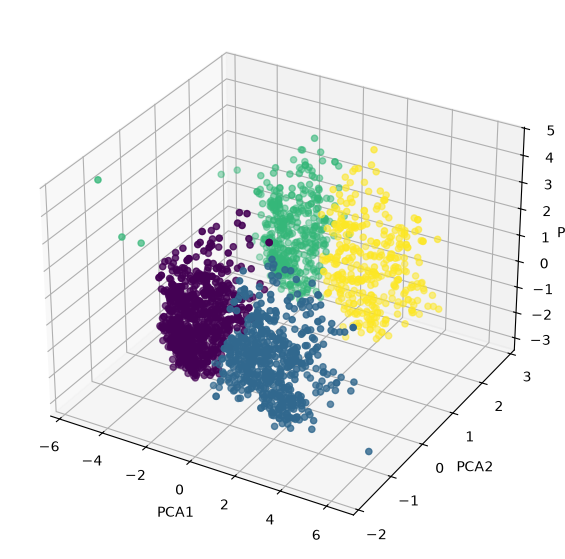

In [48]:
from sklearn.cluster import AgglomerativeClustering

k = 4

algo = AgglomerativeClustering(
    n_clusters=k,
)

labeld_alg = algo.fit_predict(X_pca)

fig = plt.figure(figsize=(8, 7))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    X_pca[:, 2],
    c=scaled
)

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")

plt.show()

# Charetrezation of Cluster

In [49]:
X["cluster"] = labeld_alg
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Custome_Tenure_Days,Total_spending,Total_children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_with_Alone,Living_with_Partner,cluster
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='cluster', ylabel='count'>

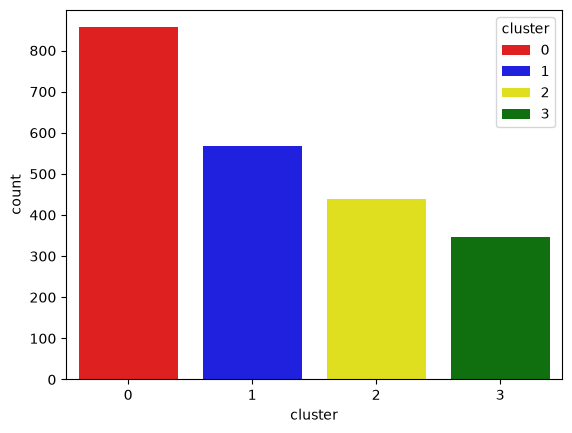

In [57]:
# plot

pal = ["red", "blue", "yellow", "green"]

sns.countplot(
    x=X["cluster"],
    palette=pal,
    hue = X["cluster"],
)

<Axes: xlabel='Total_spending', ylabel='Income'>

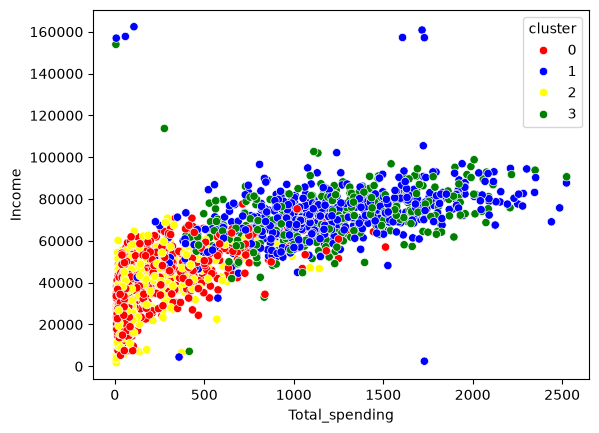

In [58]:
# compre  between Income & Spending
sns.scatterplot(
    x=X["Total_spending"],
    y=X["Income"],
    hue = X["cluster"],
    palette=pal
)

In [59]:
# cluster summary

cluster_name = X.groupby("cluster").mean()

print("Sluster Summary", cluster_name)

Sluster Summary                Income    Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                
0        38814.688084  49.113318           2.643692         3.063084   
1        71785.449912  48.810193           1.919156         5.662566   
2        36861.452273  48.034091           2.600000         2.736364   
3        71016.011527  50.380403           1.853026         5.749280   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                   0.941589           4.070093           6.477804  0.009346   
1                   5.230228           8.469244           3.520211  0.008787   
2                   0.854545           3.643182           6.659091  0.011364   
3                   5.051873           8.466859           3.726225  0.005764   

         Response        Age  Custome_Tenure_Days  Total_spending  \
c